# Workshop 5: Deep neural network for prediction

**Real-life problem:** Does a home's asking price match the price tier its features suggest? The model labels a home 'above the median price' or not; where that disagrees with a listing's asking price, the listing deserves a second look. And is a deep network worth the extra complexity over a plain logistic regression?

**My twist:** Compare a plain logistic regression with the small network, the large network and the regularised network (early stopping, dropout, L2) on the same data, fairly: fixed seeds, the scaler fitted on training data only, and five different train/validation/test splits so the spread is visible.

**Done when:** A comparison table (accuracy, precision, recall) for baseline vs small vs large vs regularised, a confusion matrix, and a verdict: is the added complexity worth it?

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: a deep network for house prices (the lecturer's baseline)

A small network, a large one, and a large one with dropout and L2, each trained once on one random split. Two things to keep in mind: the split has no random seed, so the numbers change on every run; and the scaler is fitted on all the data before splitting, a small leak. With only about 220 test homes, one accuracy number can easily be off by a point or two. Part B addresses all three.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='Do not pass an `input_shape`')   # harmless Keras 3 notice that prints a file path from your computer

import pandas as pd

df = pd.read_csv('housepricedata.csv')

dataset = df.values
X = dataset[:,0:10]
Y = dataset[:,10]

from sklearn import preprocessing
min_max_scaler = preprocessing.MinMaxScaler()
X_scale = min_max_scaler.fit_transform(X)

In [2]:
from sklearn.model_selection import train_test_split
X_train, X_val_and_test, Y_train, Y_val_and_test = train_test_split(X_scale, Y, test_size=0.3)
X_val, X_test, Y_val, Y_test = train_test_split(X_val_and_test, Y_val_and_test, test_size=0.5)
print(X_train.shape, X_val.shape, X_test.shape, Y_train.shape, Y_val.shape, Y_test.shape)

(1022, 10) (219, 10) (219, 10) (1022,) (219,) (219,)


Epoch 1/100


.../site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4511 - loss: 0.7012 - val_accuracy: 0.4018 - val_loss: 0.6963
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4873 - loss: 0.6932 - val_accuracy: 0.6301 - val_loss: 0.6878
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5890 - loss: 0.6863 - val_accuracy: 0.6438 - val_loss: 0.6806
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6125 - loss: 0.6797 - val_accuracy: 0.6941 - val_loss: 0.6740
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6663 - loss: 0.6733 - val_accuracy: 0.7215 - val_loss: 0.6676
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7231 - loss: 0.6665 - val_accuracy: 0.7717 - val_loss: 0.6608
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7691 - loss: 0.6594 - val_accuracy: 0.8037 - val_loss: 0.6539
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8033 - loss: 0.6525 - val_accuracy: 0.8037 - val_loss: 0.

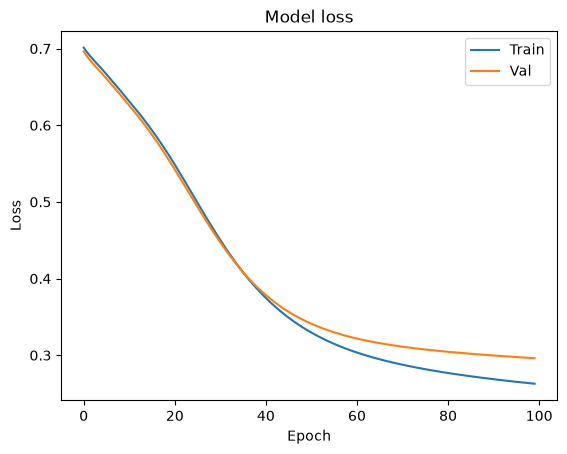

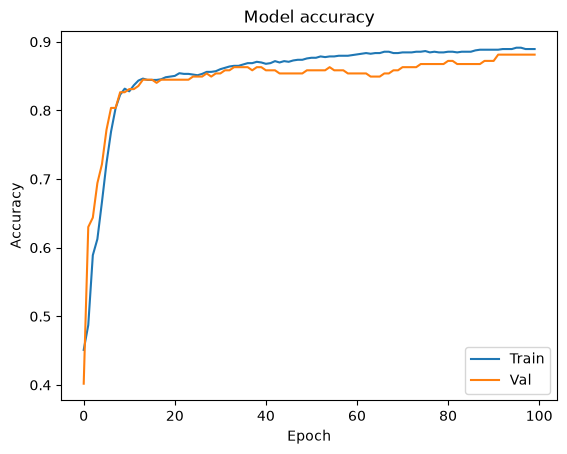

In [3]:
from keras.models import Sequential
from keras.layers import Dense
model = Sequential([
    Dense(32, activation='relu', input_shape=(10,)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid'),
])

model.compile(optimizer='sgd',
              loss='binary_crossentropy',
              metrics=['accuracy'])

hist = model.fit(X_train, Y_train,
          batch_size=32, epochs=100,
          validation_data=(X_val, Y_val))

model.evaluate(X_test, Y_test)

import matplotlib.pyplot as plt
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper right')
plt.show()

plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower right')
plt.show()

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7652 - loss: 0.4727 - val_accuracy: 0.8356 - val_loss: 0.3742
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8552 - loss: 0.3203 - val_accuracy: 0.8539 - val_loss: 0.3752
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8845 - loss: 0.2680 - val_accuracy: 0.8630 - val_loss: 0.3543
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8757 - loss: 0.2593 - val_accuracy: 0.8950 - val_loss: 0.2902
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8826 - loss: 0.2491 - val_accuracy: 0.8904 - val_loss: 0.2625
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8885 - loss: 0.2381 - val_accuracy: 0.8995 - val_loss: 0.2839
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8924 - loss: 0.2387 - val_accuracy: 0.8950 - val_loss: 0.2655
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8933 - loss: 0.2288 - val_accuracy: 0.9041 - 

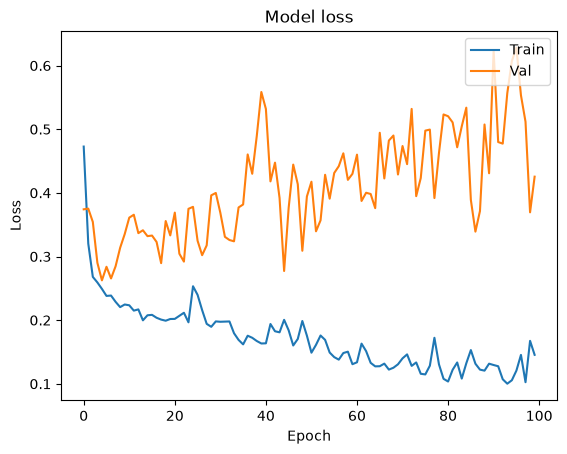

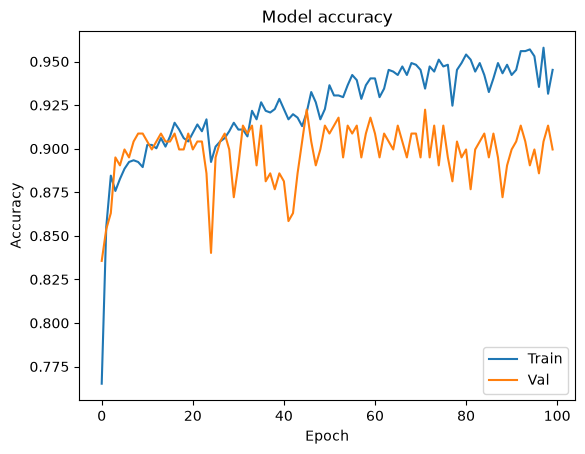

In [4]:
model_2 = Sequential([
    Dense(1000, activation='relu', input_shape=(10,)),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1, activation='sigmoid'),
])

model_2.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

hist_2 = model_2.fit(X_train, Y_train,
          batch_size=32, epochs=100,
          validation_data=(X_val, Y_val))

model_2.evaluate(X_test, Y_test)

plt.plot(hist_2.history['loss'])
plt.plot(hist_2.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper right')
plt.show()

plt.plot(hist_2.history['accuracy'])
plt.plot(hist_2.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower right')
plt.show()



In [5]:
model_2.evaluate(X_test, Y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9041 - loss: 0.6160


[0.6160262823104858, 0.9041095972061157]

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.6262 - loss: 14.2254 - val_accuracy: 0.8265 - val_loss: 3.8779
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8474 - loss: 1.6447 - val_accuracy: 0.8630 - val_loss: 0.6706
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8659 - loss: 0.5486 - val_accuracy: 0.8630 - val_loss: 0.5434
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8796 - loss: 0.4947 - val_accuracy: 0.8676 - val_loss: 0.4991
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8845 - loss: 0.4792 - val_accuracy: 0.8402 - val_loss: 0.5662
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8845 - loss: 0.4725 - val_accuracy: 0.8676 - val_loss: 0.5189
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8777 - loss: 0.4590 - val_accuracy: 0.8584 - val_loss: 0.5297
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8708 - loss: 0.4622 - val_accuracy: 0.8676 -

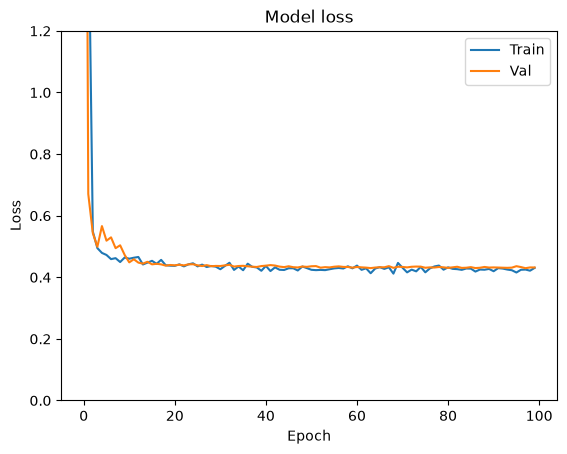

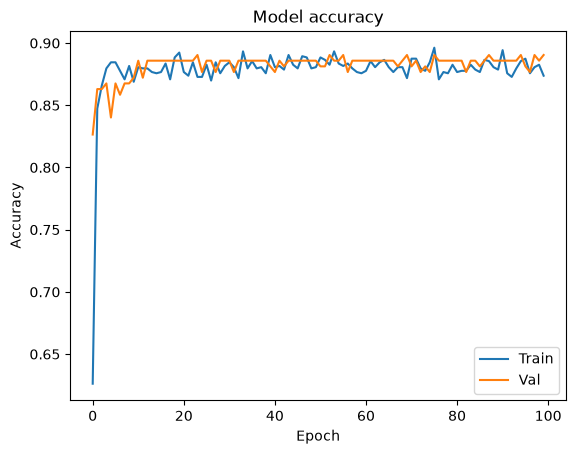

In [6]:
# OPTIONAL - Advance topic
from keras.layers import Dropout
from keras import regularizers
model_3 = Sequential([
    Dense(1000, activation='relu', kernel_regularizer=regularizers.l2(0.01), input_shape=(10,)),
    Dropout(0.3),
    Dense(1000, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1000, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1000, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1, activation='sigmoid', kernel_regularizer=regularizers.l2(0.01)),
])

model_3.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

hist_3 = model_3.fit(X_train, Y_train,
          batch_size=32, epochs=100,
          validation_data=(X_val, Y_val))

model_3.evaluate(X_test, Y_test)

plt.plot(hist_3.history['loss'])
plt.plot(hist_3.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper right')
plt.ylim(top=1.2, bottom=0)
plt.show()

plt.plot(hist_3.history['accuracy'])
plt.plot(hist_3.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower right')
plt.show()

---
## Part B: real life: is the deep network worth it?

**Question:** `AboveMedianPrice` says whether a home sold for more than the median. That makes this a **price-tier classifier**: given a home's size, quality and condition, which half of the market does it belong in? Where the model says "top half" but a listing is priced like the bottom half (or the reverse), that listing is worth a closer look. **Does a deep network classify the tier better than a plain logistic regression, and by enough to justify its complexity?**

**Fair test:** five different random splits (70% train, 15% validation, 15% test, balanced by class), a fixed seed for each, and the scaler fitted on training data only. Every network uses early stopping (it stops when the validation loss stops improving and keeps the best version) and the Adam optimiser, so the only difference between models is their *size and regularisation*. Positive class = above the median price.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

homes = pd.read_csv('housepricedata.csv')
features = [c for c in homes.columns if c != 'AboveMedianPrice']
X, y = homes[features].to_numpy(), homes['AboveMedianPrice'].to_numpy()
print(f'{len(homes):,} homes, {len(features)} features; {y.mean() * 100:.0f}% are above the median price')

def split(seed):
    """70/15/15 split, balanced by class, scaler fitted on the training part only."""
    X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.30, stratify=y, random_state=seed)
    X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=seed)
    scaler = MinMaxScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te), y_tr, y_va, y_te

In [ ]:
def small_net():
    return keras.Sequential([keras.Input(shape=(10,)), layers.Dense(32, activation='relu'), layers.Dense(32, activation='relu'),
                             layers.Dense(1, activation='sigmoid')])

def large_net():
    return keras.Sequential([keras.Input(shape=(10,))] + [layers.Dense(1000, activation='relu') for _ in range(4)] + [layers.Dense(1, activation='sigmoid')])

def regularised_net():
    l2 = regularizers.l2(0.01)
    stack = [keras.Input(shape=(10,))]
    for _ in range(4):
        stack += [layers.Dense(1000, activation='relu', kernel_regularizer=l2), layers.Dropout(0.3)]
    return keras.Sequential(stack + [layers.Dense(1, activation='sigmoid', kernel_regularizer=l2)])

NETS = {'small network': small_net, 'large network': large_net, 'large + dropout + L2': regularised_net}

def run_net(build, split_data, seed):
    X_tr, X_va, X_te, y_tr, y_va, y_te = split_data
    keras.utils.set_random_seed(seed)
    model = build()
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, batch_size=32, epochs=100, validation_data=(X_va, y_va), callbacks=[stop], verbose=0)
    return (model.predict(X_te, verbose=0).ravel() >= 0.5).astype(int), model.count_params(), time.time() - t0, len(hist.history['loss'])

In [ ]:
SEEDS = range(5)
records, preds = [], {}
for seed in SEEDS:
    data = split(seed); y_te = data[5]
    runs = {}
    t0 = time.time()
    lr = LogisticRegression(max_iter=1000).fit(data[0], data[3])
    runs['logistic regression'] = (lr.predict(data[2]), 11, time.time() - t0, 1)
    for name, build in NETS.items():
        runs[name] = run_net(build, data, seed)
    for name, (p, n_params, secs, epochs) in runs.items():
        records.append({'seed': seed, 'model': name, 'accuracy': accuracy_score(y_te, p), 'precision': precision_score(y_te, p),
                        'recall': recall_score(y_te, p), 'parameters': n_params, 'seconds': secs, 'epochs': epochs})
        preds.setdefault(name, []).append((y_te, p))
    print(f'split {seed} done')
results = pd.DataFrame(records)

### 1. The comparison

In [ ]:
order = ['logistic regression', 'small network', 'large network', 'large + dropout + L2']
g = results.groupby('model').agg(accuracy=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'), precision=('precision', 'mean'),
                                 recall=('recall', 'mean'), parameters=('parameters', 'first'), seconds=('seconds', 'mean'),
                                 epochs=('epochs', 'mean')).loc[order]
table = pd.DataFrame({'accuracy (%)': (g['accuracy'] * 100).round(1), '± spread across splits': (g['accuracy_sd'] * 100).round(1),
                      'precision (%)': (g['precision'] * 100).round(1), 'recall (%)': (g['recall'] * 100).round(1),
                      'parameters': g['parameters'].astype(int), 'training time (s)': g['seconds'].round(1), 'epochs run': g['epochs'].round(0).astype(int)})
table

In [ ]:
acc = results.pivot(index='seed', columns='model', values='accuracy')[order] * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, m in enumerate(order):
    ax.scatter([i] * len(acc), acc[m], color='grey', alpha=0.6)
    ax.plot([i - 0.2, i + 0.2], [acc[m].mean()] * 2, 'b-', lw=3)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12)
ax.set_ylabel('test accuracy (%)'); ax.set_title('Test accuracy on each of 5 splits (blue = average)')
plt.tight_layout(); plt.show()

diff = acc.sub(acc['logistic regression'], axis=0).drop(columns='logistic regression')
print('accuracy difference vs logistic regression, in points (average; splits where the network won):')
for m in diff.columns:
    print(f'  {m:22s} {diff[m].mean():+.2f}   ({(diff[m] > 0).sum()} of {len(diff)})')

- **All four models land at about 90% accuracy** (90.1% to 90.7%), within 0.6 points of one another, while any one model's accuracy moves by 2 to 3 points from split to split. The differences are noise.
- **Against the logistic regression:** the small network ties (+0.0 points, better on 2 of 5 splits), the large network is +0.2 (better on 2 of 5), and the regularised network is -0.4 (better on 1 of 5).
- **The cost of complexity:** the logistic regression has 11 numbers to fit and trains instantly. The large networks have about 3 million parameters (roughly 270,000 times more) and take several seconds to a quarter of a minute to train.
- **Regularisation didn't help**: dropout plus L2 is slightly worse and the most variable. I did not tune its settings (dropout 0.3, L2 0.01), so a better setting might close the gap, but it would still only be catching up with a model of 11 numbers.

### 2. What kind of mistakes?
All five test sets pooled (about 1,100 predictions per model). Rows are the truth, columns are the prediction.

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, m in zip(axes, order):
    yt = np.concatenate([a for a, b in preds[m]]); yp = np.concatenate([b for a, b in preds[m]])
    cm = confusion_matrix(yt, yp)
    ax.imshow(cm, cmap='Blues')
    for (r, c), v in np.ndenumerate(cm): ax.text(c, r, f'{v}', ha='center', va='center', fontsize=13)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['below', 'above']); ax.set_yticks([0, 1]); ax.set_yticklabels(['below', 'above'])
    ax.set_xlabel('predicted tier'); ax.set_title(m, fontsize=10)
axes[0].set_ylabel('actual tier')
plt.tight_layout(); plt.show()

In [ ]:
pooled = {}
for m in order:
    yt = np.concatenate([a for a, b in preds[m]]); yp = np.concatenate([b for a, b in preds[m]])
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    pooled[m] = {'predictions': len(yt), 'wrong (%)': round((fp + fn) / len(yt) * 100, 1),
                 'above-median homes missed (called below)': int(fn), 'below-median homes wrongly called above': int(fp)}
pd.DataFrame(pooled).T

- **All four models make about the same number of mistakes**: 9.3% to 9.9% of homes wrong.
- **They err in one direction more often.** About 60 expensive homes were called "below median" against about 42 cheaper homes called "above" (out of roughly 550 in each tier across the pooled test sets). So the models are more likely to undersell a home's tier than to overrate it, which is why recall is lower than precision.
- **Probably the errors sit near the median price**, where features can't separate the tiers, but I haven't checked that.

### Verdict
**No: the deep network is not worth it here.** On five fair splits, a plain logistic regression (11 numbers, instant to train) classifies a home's price tier as well as networks with 1,441 or 3 million parameters: about 90% accuracy for all four, with differences under 0.4 points against a 2 to 3 point spread between splits. The regularised network was slightly worse. The simple model is as accurate, faster, and easy to explain, because each feature's weight can be read off. A tier flag built on it would be wrong about 1 time in 10, so it is a prompt to look twice at a listing, not a verdict.

**Caveats:** one dataset of 1,460 homes whose source and date the file does not document; five splits; the networks were not tuned (Adam, early stopping with patience 10, dropout 0.3, L2 0.01); and predicting a price *tier* is not the same as spotting an *overpriced* listing.

**Next:** try gradient-boosted trees (often the strongest option on tabular data like this), and check whether the errors cluster near the median price.